# Taller MLP: ¿aprobará el estudiante?
**Objetivo:** predecir si un estudiante aprueba (1) o reprueba (0) usando un **Perceptrón Multicapa (MLP)**, que es una red neuronal sencilla.

**Pasos del taller**
1. Cargar los datos e imputar vacíos con la mediana
2. Revisar el balanceo de clases (50% / 50%)
3. Analizar los datos (y detectar una *fuga de datos*)
4. Separar entradas (X) y respuesta (y)
5. Dividir en entrenamiento y prueba
6. Estandarizar (media 0, varianza 1)
7. Entrenar el MLP
8. Evaluar: matriz de confusión, precision, recall, F1 y accuracy
9. Guardar el modelo para la app web
10. Conclusiones

## 1. Cargar los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score)
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv("dataset_estudiantes_balanceado.csv")
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (600, 8)


,Tareas,Examenes,Asistencia,Estudio_Horas,Sueno_Horas,Extracurriculares,Calificacion_Final,Aprobado
0,56.217808,33.514805,85.495792,23.999532,5.703021,1,79.671652,1
1,96.550001,42.287227,41.475215,18.962692,4.358559,1,82.650731,1
2,81.239576,34.160839,41.327413,10.124782,6.048144,0,60.380195,0
3,71.906094,27.096203,59.416613,13.791209,5.556087,1,63.816827,0
4,40.921305,29.650870,69.806012,10.043174,7.385603,0,49.874904,0


## 2. Imputar valores ausentes con la mediana
- **Imputar** = rellenar los datos que faltan.
- **Mediana** = el valor que queda en el medio cuando ordenas los datos de una columna.

In [3]:
print("Valores vacíos por columna:")
print(df.isna().sum())

Valores vacíos por columna:
Tareas                0
Examenes              0
Asistencia            0
Estudio_Horas         0
Sueno_Horas           0
Extracurriculares     0
Calificacion_Final    0
Aprobado              0
dtype: int64


In [4]:
medianas = df.median(numeric_only=True)
print("Medianas de cada columna:")
print(medianas)

df = df.fillna(medianas)

print("\nVacíos después de imputar:", df.isna().sum().sum())

Medianas de cada columna:
Tareas                65.987837
Examenes              60.025488
Asistencia            69.806012
Estudio_Horas         13.791209
Sueno_Horas            6.491089
Extracurriculares      0.000000
Calificacion_Final    74.673511
Aprobado               0.500000
dtype: float64

Vacíos después de imputar: 0


## 3. Balanceo de clases (objetivo 1 del taller)

Aprobado
1    300
0    300
Name: count, dtype: int64

Porcentaje:
Aprobado
1    50.0
0    50.0
Name: proportion, dtype: float64


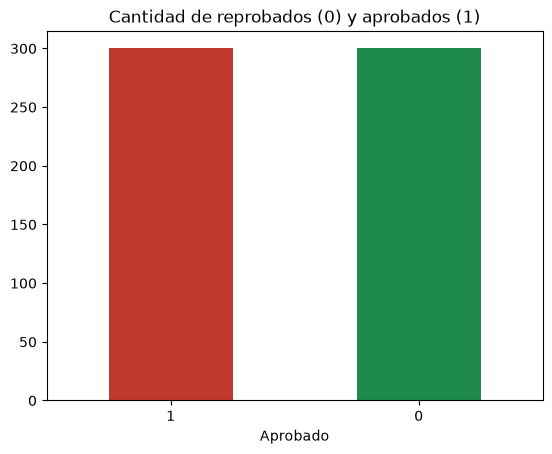

In [5]:
print(df["Aprobado"].value_counts())
print("\nPorcentaje:")
print(df["Aprobado"].value_counts(normalize=True) * 100)

df["Aprobado"].value_counts().plot(kind="bar", color=["#c0392b", "#1e8a4c"])
plt.title("Cantidad de reprobados (0) y aprobados (1)")
plt.xticks(rotation=0)
plt.show()

## 4. Analizar los datos

In [6]:
df.describe().round(2)

,Tareas,Examenes,Asistencia,Estudio_Horas,Sueno_Horas,Extracurriculares,Calificacion_Final,Aprobado
count,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.0
mean,65.03,59.62,69.61,13.51,6.52,0.41,74.67,0.5
std,20.44,23.28,17.14,6.50,1.47,0.49,14.51,0.5
min,30.35,20.37,40.30,2.04,4.00,0.00,37.55,0.0
25%,47.42,38.62,54.25,7.99,5.35,0.00,64.36,0.0
50%,65.99,60.03,69.81,13.79,6.49,0.00,74.67,0.5
75%,82.68,79.82,83.10,18.93,7.83,1.00,84.15,1.0
max,99.98,99.83,99.96,24.96,8.99,1.00,110.83,1.0


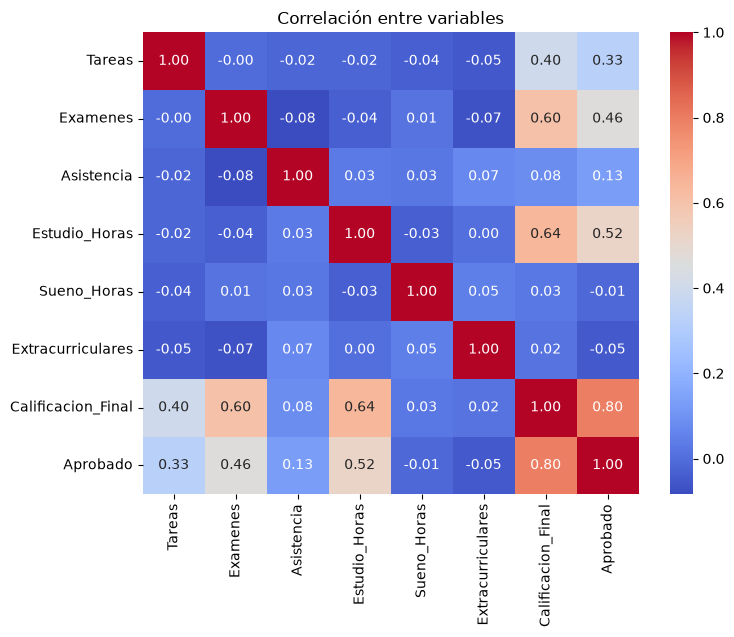

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlación entre variables")
plt.show()

### Detalle importante: fuga de datos (*data leakage*)
`Calificacion_Final` se calcula con las otras columnas y de ella sale `Aprobado`.
Si el modelo la recibe como entrada, **es como darle las respuestas del examen**.
Lo comprobamos: si todos los reprobados quedan por debajo de un corte y todos los aprobados por encima, hay fuga.

In [8]:
print(df.groupby("Aprobado")["Calificacion_Final"].agg(["min", "max", "median"]).round(2))

            min     max  median
Aprobado                       
0         37.55   74.67   64.34
1         74.68  110.83   84.15


## 5. Separar entradas (X) y respuesta (y)
**No** incluimos `Calificacion_Final` en X.

In [9]:
FEATURES = ["Tareas", "Examenes", "Asistencia", "Estudio_Horas", "Sueno_Horas", "Extracurriculares"]

X = df[FEATURES]
y = df["Aprobado"]
print("X:", X.shape, "| y:", y.shape)

X: (600, 6) | y: (600,)


## 6. Dividir en entrenamiento (80%) y prueba (20%)
- **Entrenamiento:** datos con los que el modelo aprende.
- **Prueba:** datos que nunca vio, para examinarlo de verdad.
- `stratify=y` mantiene el 50/50 en los dos grupos.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("\nAprobados en entrenamiento:", y_train.mean().round(2))
print("Aprobados en prueba       :", y_test.mean().round(2))

Entrenamiento: (480, 6) | Prueba: (120, 6)

Aprobados en entrenamiento: 0.5
Aprobados en prueba       : 0.5


## 7. Estandarizar (media 0 y varianza 1)
Las columnas tienen escalas distintas (0-100 contra 0-9 horas). Estandarizar las deja comparables.
**Regla:** el escalador aprende (`fit`) solo con entrenamiento; a prueba solo se le aplica (`transform`).

In [11]:
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)

print("Media de cada columna (entrenamiento):", X_train_esc.mean(axis=0).round(3))
print("Desviación de cada columna (entrenamiento):", X_train_esc.std(axis=0).round(3))

Media de cada columna (entrenamiento): [ 0.  0.  0. -0. -0.  0.]
Desviación de cada columna (entrenamiento): [1. 1. 1. 1. 1. 1.]


## 8. Crear y entrenar el MLP
- **2 capas ocultas:** 16 y luego 8 neuronas.
- **relu:** función que decide qué neuronas se "activan".
- **adam:** método que ajusta los pesos de la red.
- **max_iter=1000:** máximo de vueltas de aprendizaje.

In [12]:
modelo = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42,
)
modelo.fit(X_train_esc, y_train)
print("Vueltas de entrenamiento realizadas:", modelo.n_iter_)

Vueltas de entrenamiento realizadas: 399


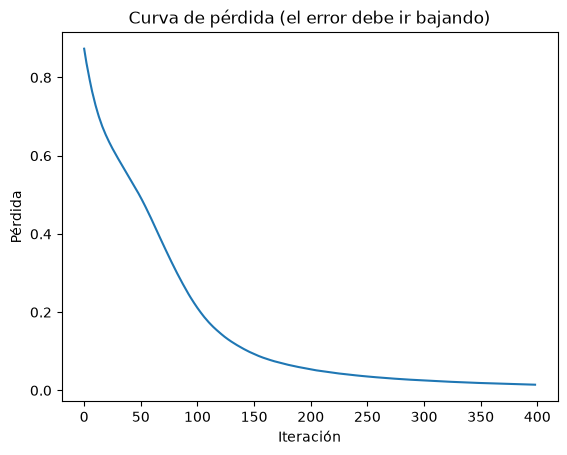

In [13]:
plt.plot(modelo.loss_curve_)
plt.title("Curva de pérdida (el error debe ir bajando)")
plt.xlabel("Iteración")
plt.ylabel("Pérdida")
plt.show()

## 9. Evaluación sobre el set de prueba independiente

In [14]:
y_pred = modelo.predict(X_test_esc)

print("Accuracy en entrenamiento:", round(accuracy_score(y_train, modelo.predict(X_train_esc)), 4))
print("Accuracy en prueba       :", round(accuracy_score(y_test, y_pred), 4))

Accuracy en entrenamiento: 1.0
Accuracy en prueba       : 0.9833


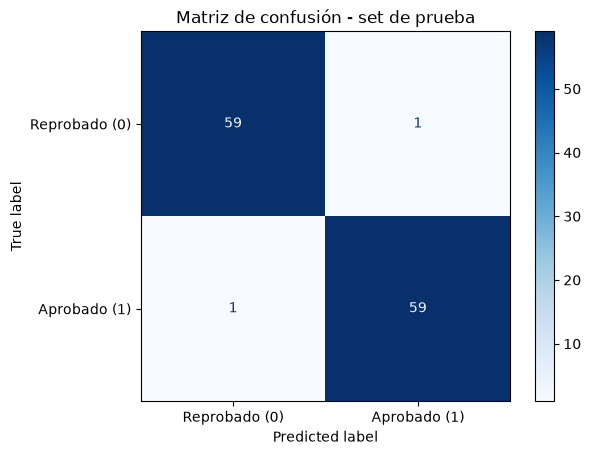

[[59  1]
 [ 1 59]]


In [15]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["Reprobado (0)", "Aprobado (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - set de prueba")
plt.show()
print(cm)

In [16]:
print(classification_report(y_test, y_pred, target_names=["Reprobado (0)", "Aprobado (1)"]))

               precision    recall  f1-score   support

Reprobado (0)       0.98      0.98      0.98        60
 Aprobado (1)       0.98      0.98      0.98        60

     accuracy                           0.98       120
    macro avg       0.98      0.98      0.98       120
 weighted avg       0.98      0.98      0.98       120



In [17]:
# Contraste de aciertos: valor real vs. predicción (primeras 15 filas de prueba)
comparacion = pd.DataFrame({
    "Real": y_test.values,
    "Predicho": y_pred,
})
comparacion["Acierto"] = comparacion["Real"] == comparacion["Predicho"]
print("Aciertos:", comparacion["Acierto"].sum(), "de", len(comparacion))
comparacion.head(15)

Aciertos: 118 de 120


,Real,Predicho,Acierto
0,0,0,True
1,0,0,True
2,1,1,True
3,1,1,True
4,1,1,True
5,1,1,True
6,0,0,True
7,1,1,True
8,1,1,True
9,1,1,True


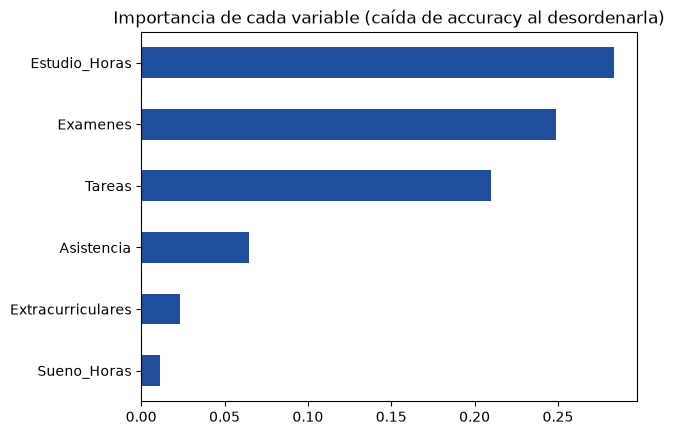

Estudio_Horas        0.2833
Examenes             0.2487
Tareas               0.2100
Asistencia           0.0646
Extracurriculares    0.0233
Sueno_Horas          0.0112
dtype: float64


In [18]:
# ¿Qué variables pesan más? (importancia por permutación)
imp = permutation_importance(modelo, X_test_esc, y_test, n_repeats=20, random_state=42)
importancias = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
importancias.plot(kind="barh", color="#1f4e9c")
plt.title("Importancia de cada variable (caída de accuracy al desordenarla)")
plt.show()
print(importancias.sort_values(ascending=False).round(4))

## 10. Guardar el modelo para la app web

In [19]:
joblib.dump(modelo, "modelo_mlp.pkl")
joblib.dump(escalador, "escalador.pkl")
print("Guardados: modelo_mlp.pkl y escalador.pkl")

Guardados: modelo_mlp.pkl y escalador.pkl


In [20]:
# Prueba rápida: un estudiante nuevo
nuevo = pd.DataFrame([[85, 80, 95, 14, 7, 1]], columns=FEATURES)
nuevo_esc = escalador.transform(nuevo)
print("Predicción:", "APROBADO" if modelo.predict(nuevo_esc)[0] == 1 else "REPROBADO")
print("Probabilidad de aprobar:", round(modelo.predict_proba(nuevo_esc)[0][1], 3))

Predicción: APROBADO
Probabilidad de aprobar: 1.0


## 11. Conclusiones

**Sobre los datos**
- El dataset tiene 600 estudiantes, **sin valores vacíos**, y ya está **balanceado (300 aprobados y 300 reprobados)**. La imputación con mediana se aplicó igual, como pide el taller, pero no modificó nada.
- **Fuga de datos:** `Aprobado` sale de cortar `Calificacion_Final` en su mediana (cerca de 74.67). Si se hubiera usado como entrada, el modelo habría "copiado" la respuesta y las métricas no serían confiables. Por eso se excluyó.
- Las variables que más se relacionan con aprobar son **Estudio_Horas, Exámenes y Tareas**. **Asistencia** influye poco, y **Sueño_Horas** y **Extracurriculares** casi nada.

**Sobre el modelo (MLP con capas 16 y 8)**
- Accuracy en prueba: **98.3%** (118 aciertos de 120). Matriz de confusión: 59 reprobados y 59 aprobados bien clasificados, **1 falso positivo y 1 falso negativo**.
- Precision, recall y F1 dieron **0.98 en ambas clases**. Al estar balanceado el dataset, el modelo no favorece a ninguna clase.
- Importancia por permutación (cuánto cae el accuracy al desordenar una variable): **Estudio_Horas ≈ 0.28, Exámenes ≈ 0.25, Tareas ≈ 0.21**, Asistencia ≈ 0.06, Extracurriculares ≈ 0.02 y Sueño_Horas ≈ 0.01.

**Sobre el uso de las métricas**
- **Accuracy** sola es suficiente aquí porque las clases están 50/50. Con clases desbalanceadas engañaría.
- **Recall** importa en este problema: un falso negativo es un estudiante en riesgo que el modelo no detecta, y se perdería la oportunidad de ayudarlo. **Precision** importa para no gastar apoyo en estudiantes que no lo necesitan.
- **La matriz de confusión** permite ver *qué tipo* de error se comete, algo que el accuracy no muestra.

**Limitaciones**
- El accuracy de entrenamiento fue 100% y el de prueba 98.3%: hay una **ligera diferencia (algo de sobreajuste)**, aunque pequeña.
- El set de prueba tiene solo 120 registros, así que un error más o menos mueve el accuracy cerca de 1%. Se podría confirmar con **validación cruzada**.
- La nota final se calcula como combinación lineal de las variables, así que el problema es "fácil". Con datos reales (más ruido) el rendimiento probablemente sería menor.
- El modelo usa solo 6 variables; no incluye factores como motivación, trabajo o situación económica.
